# Simulation results: how much does the quadratic hedge help?

The results below come from `scripts/run_simulations.py` with 100,000 paths per scenario (about 20 minutes on one core). A dealer sells an option at its model value at $X_0 = 0$ and hedges it until maturity with either Merton's hedge or the quadratic hedge. The main metric is the variance reduction

$$1 - \frac{\operatorname{Var}(\text{PnL}_{\text{quadratic}})}{\operatorname{Var}(\text{PnL}_{\text{Merton}})}.$$

Both strategies run on the same paths, and scenarios that share a true model share paths as well, so comparisons across scenarios are not driven by sampling noise. Error bars are 95% confidence intervals from the delta method on the paired squared deviations (see `jdhedge.hedging.variance_reduction`; a unit test checks it against a bootstrap).

Base case: ATM straddle, $\sigma = 0.2$, $\lambda = 2$, $m = 0$, $\delta = 0.3$, $T = 1$, 20 rebalancing dates, no transaction costs. The jump share of the variance is $\lambda\delta^2/\sigma^2 = 4.5$.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
FIGURES = ROOT / "figures"
df = pd.read_csv(ROOT / "results" / "scenarios.csv")
df["vr"] = 100 * df["var_reduction"]
df["ci"] = 196 * df["var_reduction_se"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

def table(frame, cols):
    out = frame[cols].copy()
    out["variance reduction (%)"] = [f"{v:.1f} ± {c:.1f}" for v, c in zip(frame["vr"], frame["ci"])]
    return out.reset_index(drop=True)

## 1. Base case

The quadratic hedge lowers the P&L variance by about 10%, and it also trades less and cuts the tails. Merton's hedge is the steeper of the two (notebook 02), so it rebalances more and still leaves the fat left tail that comes from jumps.

In [2]:
base = df[(df.group == "frequency") & (df.n_steps == 20)].iloc[0]
summary = pd.DataFrame({
    "Merton": [base.std_merton, base.q01_merton, base.kurtosis_merton, base.traded_merton],
    "quadratic": [base.std_quadratic, base.q01_quadratic, base.kurtosis_quadratic, base.traded_quadratic],
}, index=["P&L standard deviation", "1% quantile of P&L", "excess kurtosis", "total units traded"])
summary["change (%)"] = 100 * (summary["quadratic"] / summary["Merton"] - 1)
print(f"Variance reduction: {base.vr:.1f}% ± {base.ci:.1f}%")
summary.round(3)

Variance reduction: 10.4% ± 0.6%


,Merton,quadratic,change (%)
P&L standard deviation,0.216,0.205,-5.367
1% quantile of P&L,-0.750,-0.616,-17.760
excess kurtosis,4.258,1.881,-55.810
total units traded,3.007,2.310,-23.187


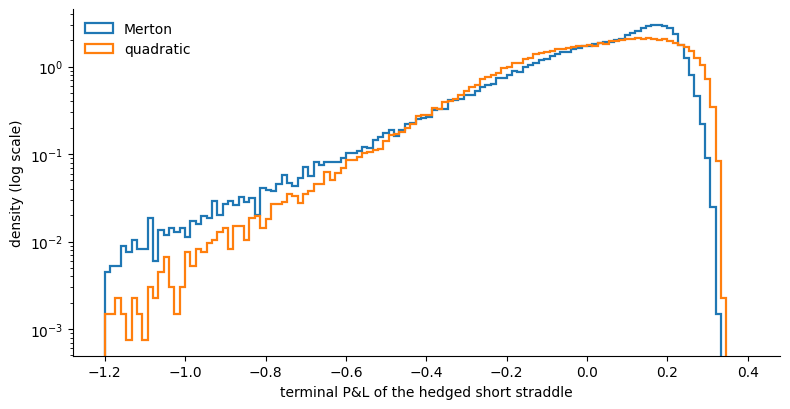

In [3]:
pnl = np.load(ROOT / "results" / "base_case_pnl.npz")
bins = np.linspace(-1.2, 0.4, 121)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(pnl["merton"], bins=bins, histtype="step", lw=1.6, density=True, label="Merton")
ax.hist(pnl["quadratic"], bins=bins, histtype="step", lw=1.6, density=True, label="quadratic")
ax.set_yscale("log")
ax.set_xlabel("terminal P&L of the hedged short straddle")
ax.set_ylabel("density (log scale)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "pnl_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Jump share and rebalancing frequency

The advantage grows steadily with the jump share of the variance. It is negligible when diffusion dominates and reaches about 16% at a jump share of 20.

It also grows with the rebalancing frequency and levels off around 12.5%. More frequent rebalancing removes diffusion risk for both strategies, and what is left is jump risk, which is exactly the part the quadratic hedge is designed for. With a single hedge at $t = 0$ both strategies hold nothing, because the straddle's hedge is zero at the money (notebook 01, section 7), so that point is zero by construction.

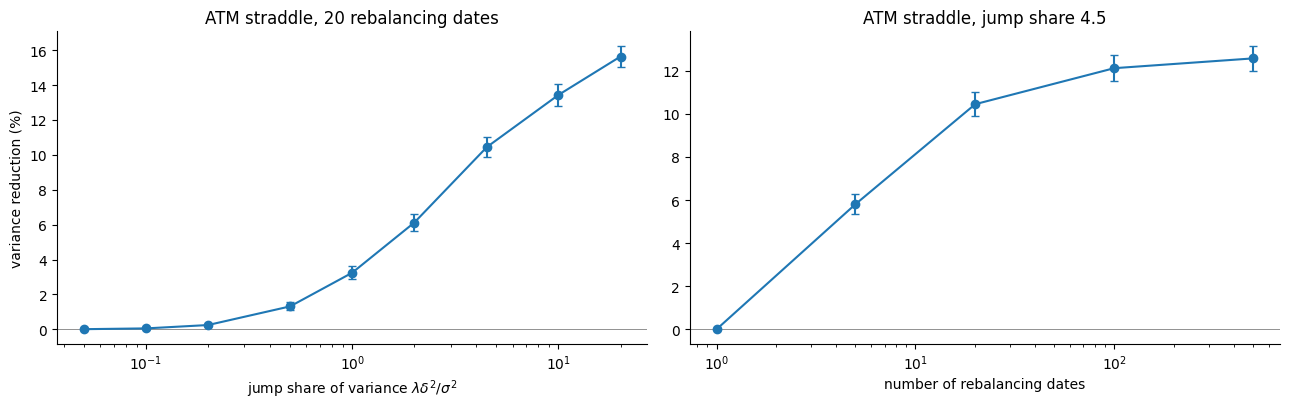

,n_steps,traded_merton,traded_quadratic,variance reduction (%)
0,1,0.000000,0.000000,0.0 ± 0.0
1,5,1.841651,1.427705,5.8 ± 0.5
2,20,3.006860,2.309665,10.4 ± 0.6
3,100,4.977822,3.870841,12.1 ± 0.6
4,500,9.033381,7.117471,12.6 ± 0.6


In [4]:
regime = df[df.group == "regime"].sort_values("jump_share")
freq = df[df.group == "frequency"].sort_values("n_steps")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].errorbar(regime.jump_share, regime.vr, yerr=regime.ci, fmt="o-", capsize=3)
axes[0].set_xscale("log")
axes[0].set_xlabel(r"jump share of variance $\lambda\delta^2/\sigma^2$")
axes[0].set_ylabel("variance reduction (%)")
axes[0].set_title("ATM straddle, 20 rebalancing dates")
axes[1].errorbar(freq.n_steps, freq.vr, yerr=freq.ci, fmt="o-", capsize=3)
axes[1].set_xscale("log")
axes[1].set_xlabel("number of rebalancing dates")
axes[1].set_title("ATM straddle, jump share 4.5")
for ax in axes:
    ax.axhline(0, color="grey", lw=0.6)
fig.tight_layout()
fig.savefig(FIGURES / "regime_and_frequency.png", dpi=150, bbox_inches="tight")
plt.show()
table(freq, ["n_steps", "traded_merton", "traded_quadratic"])

## 3. Payoffs

The straddle is the least favourable case for the quadratic hedge. The three portfolios with several strikes gain between 23% and 34%. Their value functions have more curvature in more places, so a jump changes the option's value in ways a local delta does not anticipate, and those are the changes the quadratic hedge regresses on.

In [5]:
table(df[df.group == "payoff"], ["payoff", "std_merton", "std_quadratic", "kurtosis_merton", "kurtosis_quadratic"]).round(3)

,payoff,std_merton,std_quadratic,kurtosis_merton,kurtosis_quadratic,variance reduction (%)
0,ATM straddle,0.216,0.205,4.258,1.881,10.4 ± 0.6
1,W-profile,0.088,0.072,6.436,2.610,34.0 ± 0.8
2,Risk reversal,0.103,0.083,7.300,1.540,34.4 ± 0.7
3,Call ratio spread,0.258,0.226,11.212,5.270,23.5 ± 0.7


## 4. Transaction costs

With a proportional cost $c$ per unit traded, the advantage shrinks but stays positive over the whole range tested. The quadratic hedge trades about 23% less, which offsets part of the cost. The costs themselves add variance to both P&Ls, and that dilutes the relative difference.

In [6]:
table(df[df.group == "cost"], ["cost", "traded_merton", "traded_quadratic"]).round(3)

,cost,traded_merton,traded_quadratic,variance reduction (%)
0,0.000,3.007,2.31,10.4 ± 0.6
1,0.001,3.007,2.31,10.3 ± 0.6
2,0.003,3.007,2.31,10.0 ± 0.6
3,0.010,3.007,2.31,9.1 ± 0.6
4,0.030,3.007,2.31,7.0 ± 0.6
5,0.100,3.007,2.31,4.2 ± 0.7


## 5. Model misspecification

Here the paths come from the base model while both hedgers use a model with one parameter shifted. Both strategies are misspecified in the same way, so the numbers measure how the gap between them moves. They do not measure the absolute cost of using the wrong model.

The patterns are the same at every rebalancing frequency, and the table below explains them. The quadratic hedge is robust to errors in $\sigma$ and $\lambda$: its P&L standard deviation stays between 0.205 and 0.206 across the whole range. Merton's hedge is not. Underestimating $\sigma$ or $\lambda$ makes it steeper, so it trades more and does worse, which widens the gap. Overestimating them smooths it toward the quadratic hedge and narrows the gap. Errors in the jump size $\delta$ are different, because they hurt the quadratic hedge directly. With $\delta$ 40% too high the two hedges are roughly tied at 5 rebalancing dates. In no scenario is Merton's hedge significantly better.

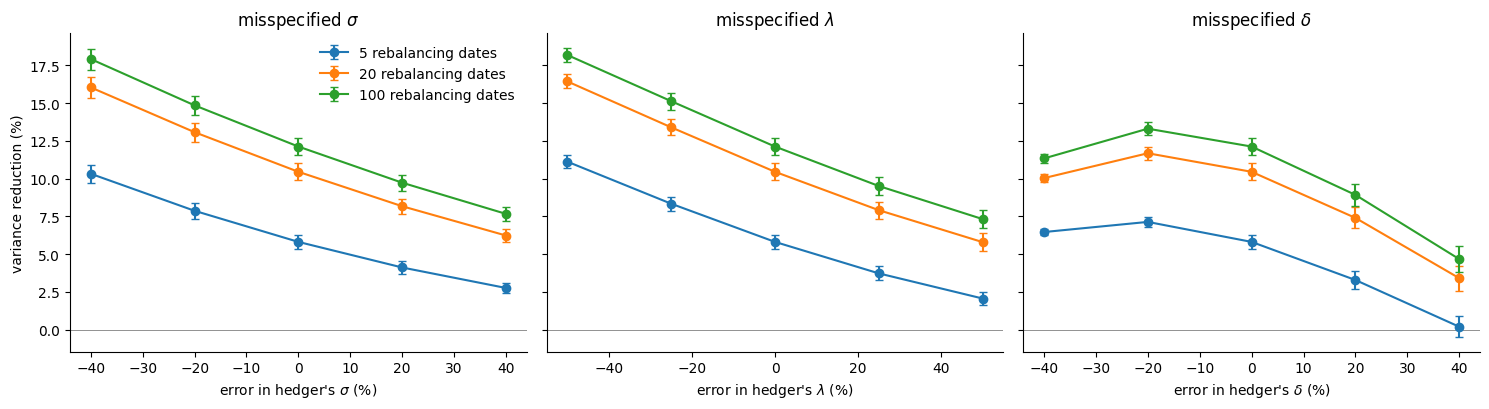

Lowest lower confidence bound across 45 scenarios: -0.50%


In [7]:
mis = df[df.group.str.startswith("misspec")].copy()
mis["param"] = mis.group.str.replace("misspec_", "")
mis["shift"] = [round(100 * (getattr(r, f"{r.param}_model") / getattr(r, f"{r.param}_true") - 1))
                for r in mis.itertuples()]
names = {"sigma": r"$\sigma$", "lam": r"$\lambda$", "delta": r"$\delta$"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (param, label) in zip(axes, names.items()):
    for n in (5, 20, 100):
        sub = mis[(mis.param == param) & (mis.n_steps == n)].sort_values("shift")
        ax.errorbar(sub["shift"], sub.vr, yerr=sub.ci, fmt="o-", capsize=3, label=f"{n} rebalancing dates")
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_xlabel(f"error in hedger's {label} (%)")
    ax.set_title(f"misspecified {label}")
axes[0].set_ylabel("variance reduction (%)")
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "misspecification.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Lowest lower confidence bound across {len(mis)} scenarios: {(mis.vr - mis.ci).min():.2f}%")

In [8]:
table(mis[mis.n_steps == 20], ["param", "shift", "std_merton", "std_quadratic", "traded_merton", "traded_quadratic"]).round(3)

,param,shift,std_merton,std_quadratic,traded_merton,traded_quadratic,variance reduction (%)
0,sigma,-40,0.224,0.205,3.198,2.276,16.0 ± 0.7
1,sigma,-20,0.220,0.205,3.098,2.295,13.1 ± 0.6
2,sigma,0,0.216,0.205,3.007,2.310,10.4 ± 0.6
3,sigma,20,0.214,0.205,2.921,2.319,8.2 ± 0.5
4,sigma,40,0.212,0.205,2.840,2.321,6.2 ± 0.4
5,lam,-50,0.226,0.206,3.273,2.581,16.4 ± 0.5
6,lam,-25,0.220,0.205,3.128,2.420,13.4 ± 0.5
7,lam,0,0.216,0.205,3.007,2.310,10.4 ± 0.6
8,lam,25,0.214,0.205,2.904,2.226,7.9 ± 0.6
9,lam,50,0.212,0.205,2.816,2.158,5.8 ± 0.6


## Summary

1. In the base case the quadratic hedge reduces P&L variance by about 10%, trades about 23% less, shrinks the 1% loss quantile by about 18% and more than halves the excess kurtosis.
2. The advantage rises with the jump share of the variance and with rebalancing frequency, so it is largest exactly where Merton's hedge is steepest: jump-dominated dynamics and frequent hedging close to expiry.
3. For portfolios with several strikes the gain is 23% to 34%.
4. The advantage survives proportional transaction costs and moderate parameter errors. Overestimating the jump size is the error that erodes it most.

A limitation: all scenarios start at the money. The one-off result, zero by symmetry for the straddle, would differ for paths starting away from the strike.